In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

train = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")
features = pd.read_csv("../data/raw/UNSW-NB15_features.csv", encoding="latin1")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (175341, 45)
Test: (82332, 45)


In [7]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


In [8]:
print(train.dtypes.value_counts())
train.dtypes

int64      30
float64    11
object      4
Name: count, dtype: int64


id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

In [9]:
missing = train.isnull().sum()
missing_pct = (missing / len(train)) * 100
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_df[missing_df["missing_count"] > 0].sort_values("missing_pct", ascending=False)

,missing_count,missing_pct


label
1    119341
0     56000
Name: count, dtype: int64
label
1    68.062233
0    31.937767
Name: proportion, dtype: float64


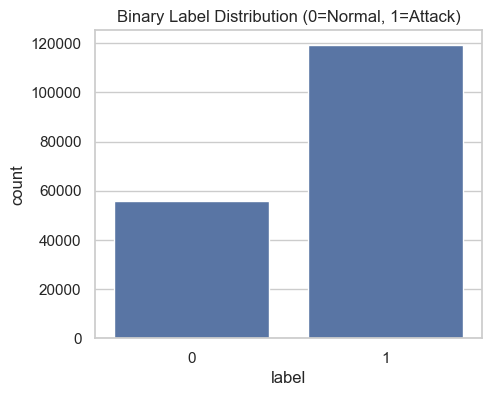

In [10]:
print(train["label"].value_counts())
print(train["label"].value_counts(normalize=True) * 100)

plt.figure(figsize=(5,4))
sns.countplot(x="label", data=train)
plt.title("Binary Label Distribution (0=Normal, 1=Attack)")
plt.show()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


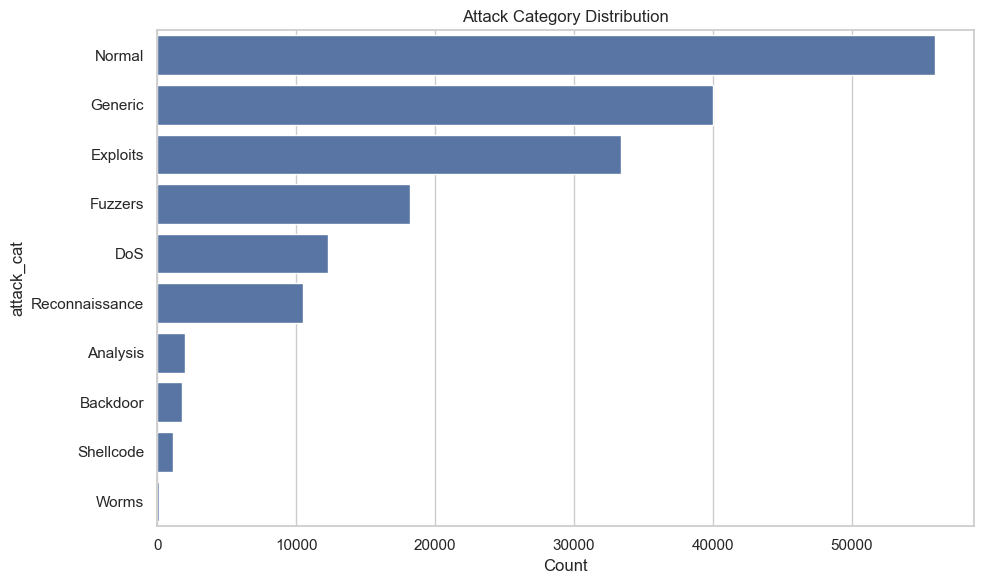

In [11]:
attack_counts = train["attack_cat"].value_counts(dropna=False)
print(attack_counts)

plt.figure(figsize=(10,6))
sns.countplot(y="attack_cat", data=train, order=attack_counts.index)
plt.title("Attack Category Distribution")
plt.xlabel("Count")
plt.tight_layout()
plt.savefig("../reports/figures/attack_cat_distribution.png")
plt.show()

In [12]:
for col in ["proto", "service", "state"]:
    print(f"\n--- {col} ({train[col].nunique()} unique values) ---")
    print(train[col].value_counts().head(10))


--- proto (133 unique values) ---
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
ipv6        201
mobile      201
Name: count, dtype: int64

--- service (13 unique values) ---
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
Name: count, dtype: int64

--- state (9 unique values) ---
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64


In [13]:
numeric_cols = train.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ["id", "label"]]

summary = train[numeric_cols].agg(["mean", "std", "min", "max", "skew"]).T
summary["kurtosis"] = train[numeric_cols].kurtosis()
summary.sort_values("skew", ascending=False)

,mean,std,min,max,skew,kurtosis
trans_depth,1.059821e-01,7.769108e-01,0.0,1.720000e+02,167.335829,34407.853786
response_body_len,2.144292e+03,5.420797e+04,0.0,6.558056e+06,76.340075,7750.978239
sbytes,8.844844e+03,1.747656e+05,28.0,1.296523e+07,45.303443,2314.880239
sloss,4.953000e+00,6.600506e+01,0.0,4.803000e+03,44.753662,2277.960322
dloss,6.948010e+00,5.273300e+01,0.0,5.484000e+03,41.380270,2942.867138
spkts,2.029866e+01,1.368876e+02,1.0,9.616000e+03,40.217703,1964.352894
dbytes,1.492892e+04,1.436542e+05,0.0,1.465555e+07,39.760864,2735.831070
dpkts,1.896959e+01,1.102583e+02,0.0,1.097400e+04,36.764114,2465.519335
dinpkt,8.821630e+01,9.870932e+02,0.0,5.671682e+04,29.679512,1158.268746
djit,6.043538e+02,4.061043e+03,0.0,2.893883e+05,29.543830,1336.151117


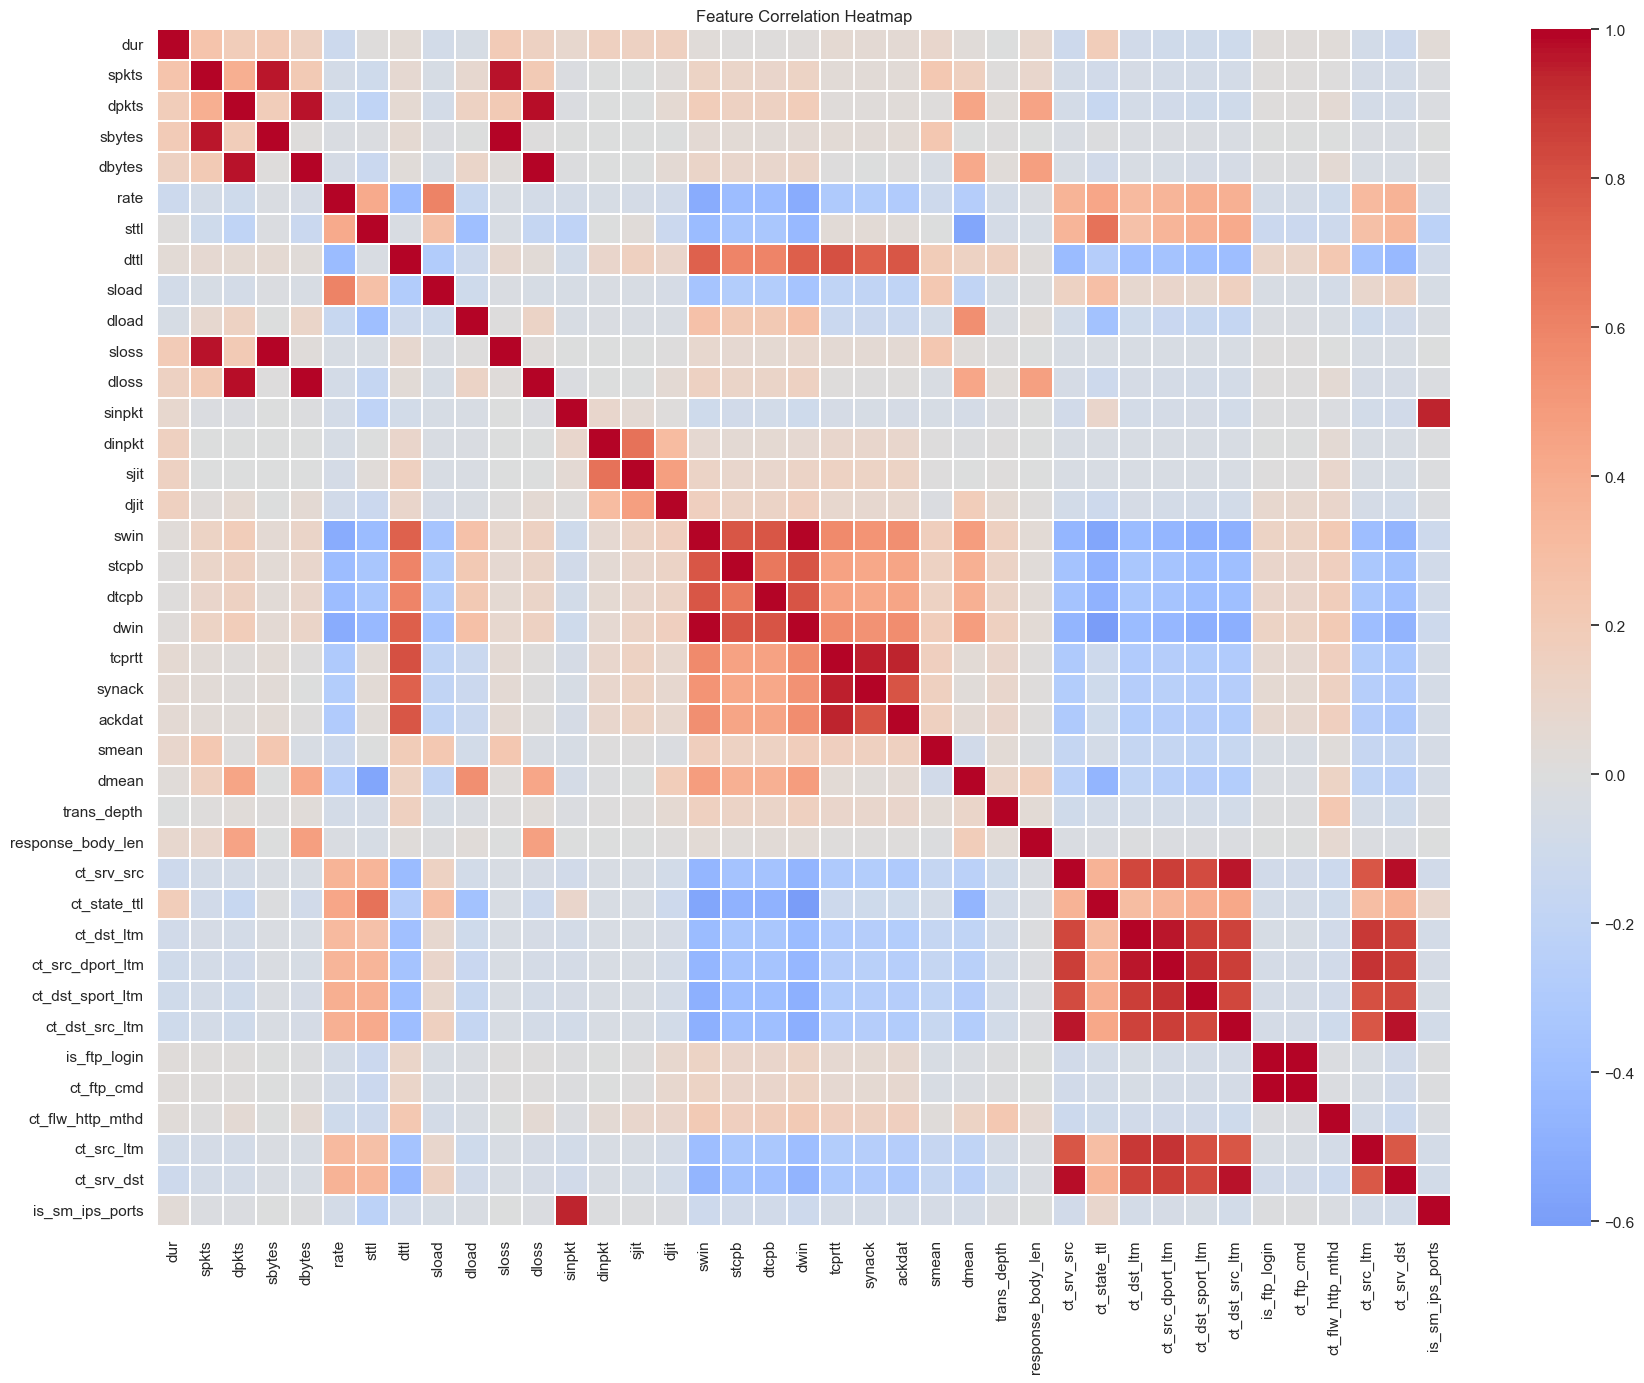

In [14]:
plt.figure(figsize=(18,14))
corr = train[numeric_cols].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_heatmap.png")
plt.show()

In [15]:
corr_matrix = corr.abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "correlation"})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs["correlation"] > 0.85].sort_values("correlation", ascending=False)
high_corr_pairs

,feature_1,feature_2,correlation
726,is_ftp_login,ct_ftp_cmd,1.000000
152,dbytes,dloss,0.996504
117,sbytes,sloss,0.996109
490,swin,dwin,0.990140
684,ct_srv_src,ct_srv_dst,0.980323
83,dpkts,dloss,0.978636
724,ct_dst_src_ltm,ct_srv_dst,0.972370
76,dpkts,dbytes,0.971907
46,spkts,sloss,0.971069
679,ct_srv_src,ct_dst_src_ltm,0.967138


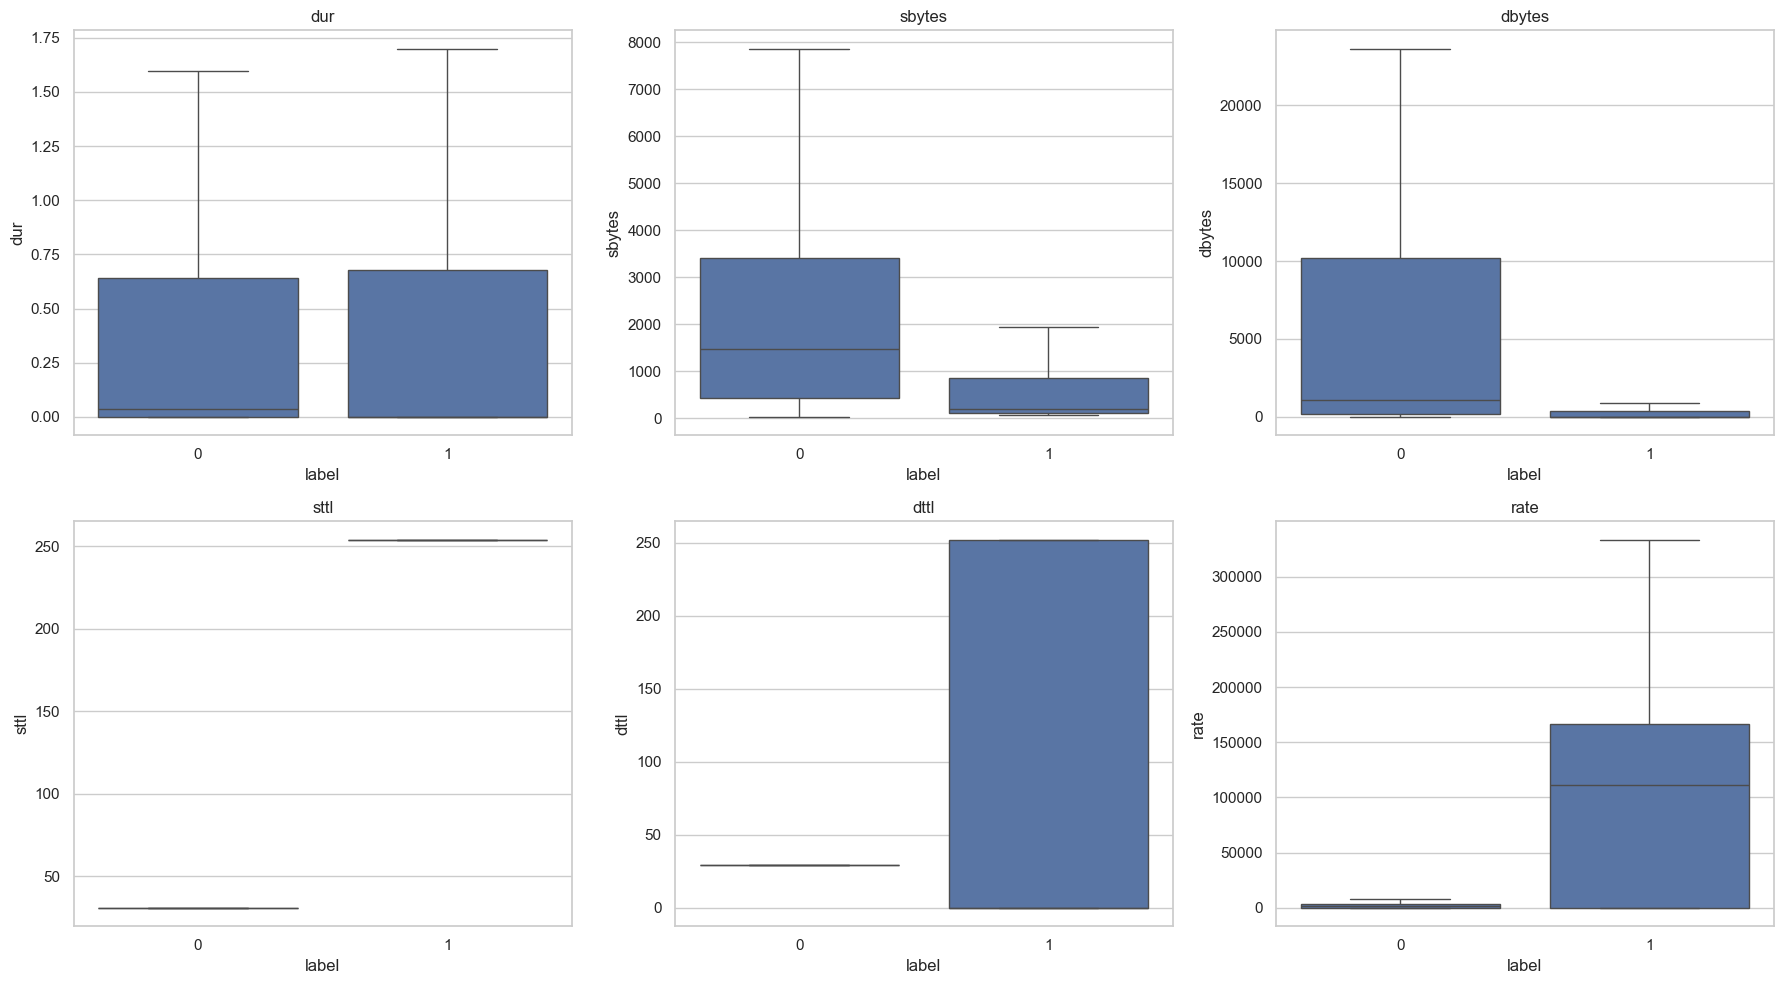

In [16]:
key_features = ["dur", "sbytes", "dbytes", "sttl", "dttl", "rate"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), key_features):
    sns.boxplot(x="label", y=col, data=train, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../reports/figures/feature_by_label_boxplots.png")
plt.show()

In [17]:
print("Train label %:\n", train["label"].value_counts(normalize=True) * 100)
print("\nTest label %:\n", test["label"].value_counts(normalize=True) * 100)

print("\nTrain attack_cat %:\n", train["attack_cat"].value_counts(normalize=True) * 100)
print("\nTest attack_cat %:\n", test["attack_cat"].value_counts(normalize=True) * 100)

Train label %:
 label
1    68.062233
0    31.937767
Name: proportion, dtype: float64

Test label %:
 label
1    55.060001
0    44.939999
Name: proportion, dtype: float64

Train attack_cat %:
 attack_cat
Normal            31.937767
Generic           22.812691
Exploits          19.044605
Fuzzers           10.370649
DoS                6.994371
Reconnaissance     5.983198
Analysis           1.140635
Backdoor           0.995774
Shellcode          0.646169
Worms              0.074141
Name: proportion, dtype: float64

Test attack_cat %:
 attack_cat
Normal            44.939999
Generic           22.920614
Exploits          13.520867
Fuzzers            7.362872
DoS                4.966477
Reconnaissance     4.246223
Analysis           0.822281
Backdoor           0.708109
Shellcode          0.459117
Worms              0.053442
Name: proportion, dtype: float64


In [18]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test:", test.duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in test: 0


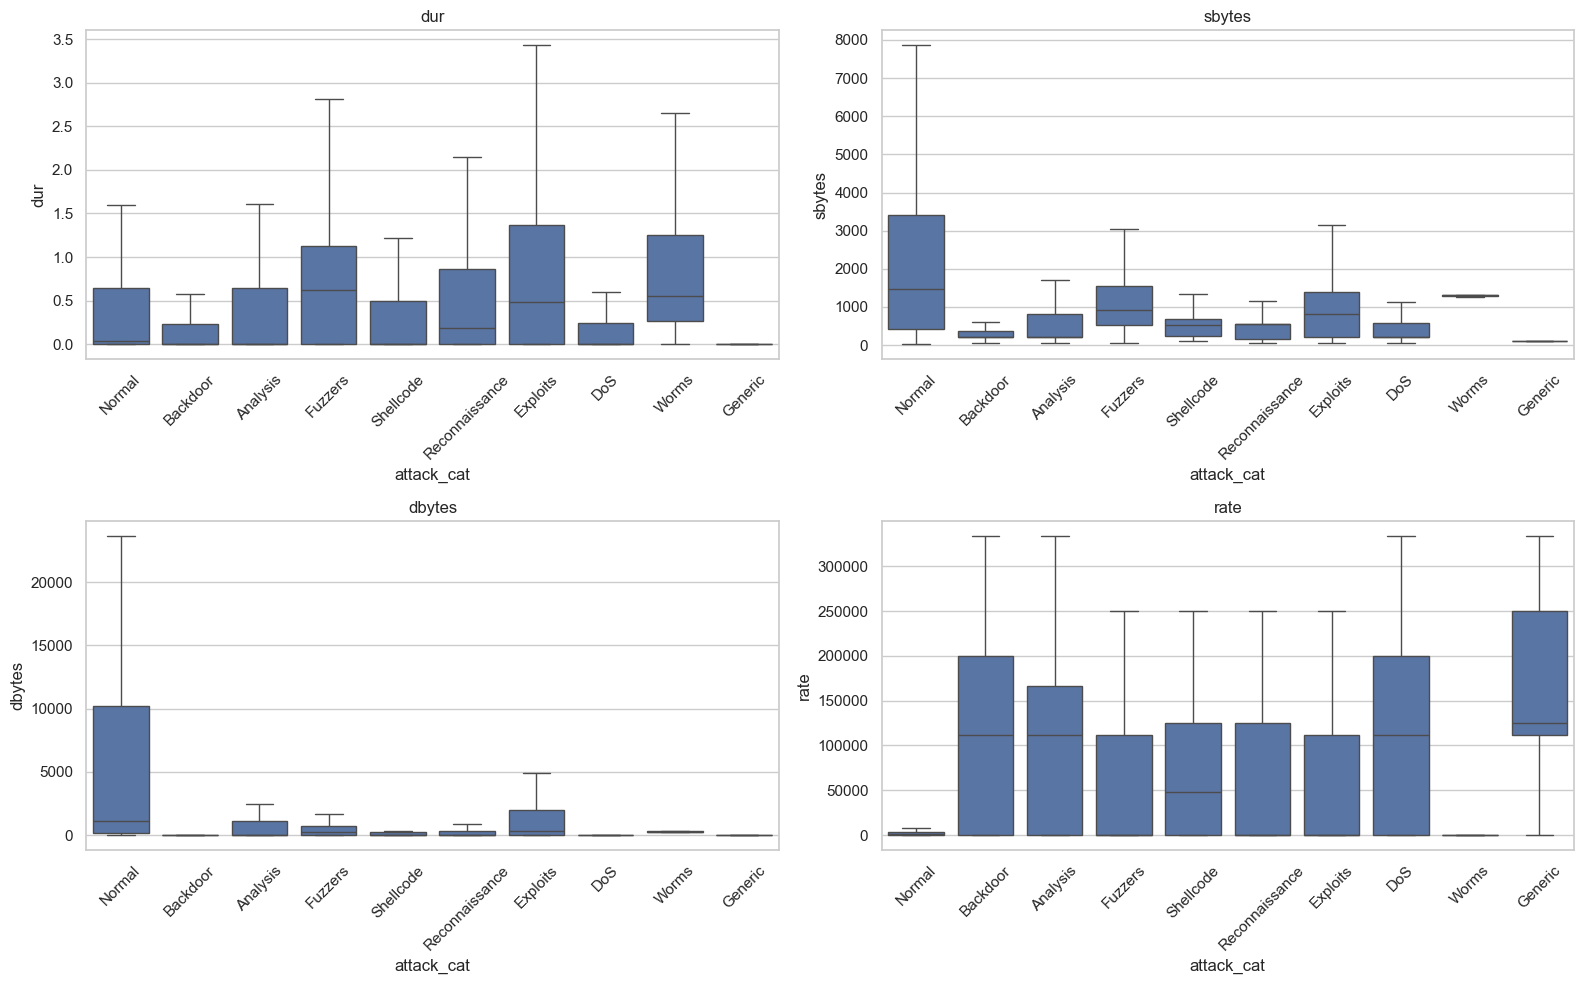

In [19]:
key_features = ["dur", "sbytes", "dbytes", "rate"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.flatten(), key_features):
    sns.boxplot(x="attack_cat", y=col, data=train, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig("../reports/figures/feature_by_attack_type.png")
plt.show()

In [20]:
pd.crosstab(train["attack_cat"], train["state"], normalize="index").round(2)

state,CON,ECO,FIN,INT,PAR,REQ,RST,URN,no
attack_cat,,,,,,,,,
Analysis,0.00,0.0,0.28,0.70,0.0,0.01,0.0,0.0,0.0
Backdoor,0.03,0.0,0.16,0.79,0.0,0.02,0.0,0.0,0.0
DoS,0.02,0.0,0.18,0.78,0.0,0.02,0.0,0.0,0.0
Exploits,0.02,0.0,0.59,0.38,0.0,0.01,0.0,0.0,0.0
Fuzzers,0.00,0.0,0.65,0.33,0.0,0.02,0.0,0.0,0.0
Generic,0.00,0.0,0.01,0.99,0.0,0.00,0.0,0.0,0.0
Normal,0.22,0.0,0.66,0.10,0.0,0.02,0.0,0.0,0.0
Reconnaissance,0.00,0.0,0.49,0.50,0.0,0.01,0.0,0.0,0.0
Shellcode,0.00,0.0,0.49,0.51,0.0,0.00,0.0,0.0,0.0


In [21]:
for col in numeric_cols:
    top_val_pct = train[col].value_counts(normalize=True).iloc[0]
    if top_val_pct > 0.95:
        print(f"{col}: {top_val_pct:.2%} of rows are the same value")

is_ftp_login: 98.54% of rows are the same value
ct_ftp_cmd: 98.54% of rows are the same value
is_sm_ips_ports: 98.42% of rows are the same value


In [22]:
zero_pct = (train[numeric_cols] == 0).mean().sort_values(ascending=False)
zero_pct.head(15)

ct_ftp_cmd           0.985360
is_ftp_login         0.985360
is_sm_ips_ports      0.984248
response_body_len    0.935588
trans_depth          0.898255
ct_flw_http_mthd     0.898255
dloss                0.551137
ackdat               0.549221
tcprtt               0.549216
synack               0.549216
dwin                 0.548947
dtcpb                0.548942
stcpb                0.548908
sloss                0.544356
swin                 0.544054
dtype: float64

In [23]:
train[["dur", "sbytes", "dbytes", "rate", "spkts", "dpkts"]].describe(percentiles=[.5, .9, .95, .99])

,dur,sbytes,dbytes,rate,spkts,dpkts
count,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000
mean,1.359389,8.844844e+03,1.492892e+04,9.540619e+04,20.298664,18.969591
std,6.480249,1.747656e+05,1.436542e+05,1.654010e+05,136.887597,110.258271
min,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,1.000000,0.000000
50%,0.001582,4.300000e+02,1.640000e+02,3.225807e+03,2.000000,2.000000
90%,1.510076,4.190000e+03,1.016800e+04,2.500000e+05,48.000000,38.000000
95%,3.079511,1.366200e+04,3.907600e+04,3.333333e+05,64.000000,62.000000
99%,45.353334,7.412540e+04,4.743678e+05,1.000000e+06,234.000000,400.000000
max,59.999989,1.296523e+07,1.465555e+07,1.000000e+06,9616.000000,10974.000000


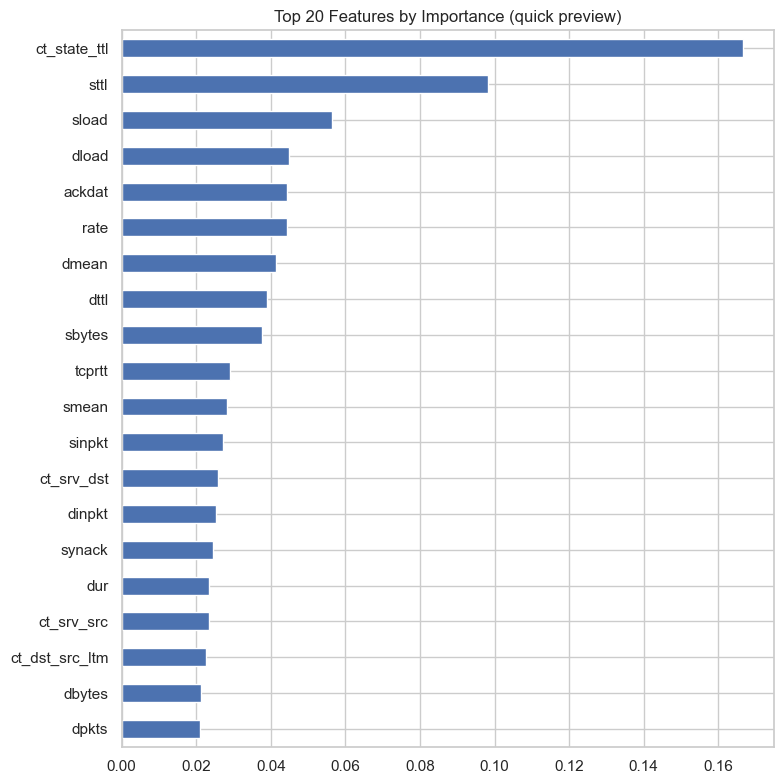

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Quick-and-dirty encoding just for this preview (not the real pipeline)
temp = train.copy()
for col in ["proto", "service", "state"]:
    temp[col] = LabelEncoder().fit_transform(temp[col])

X_temp = temp[numeric_cols + ["proto", "service", "state"]]
y_temp = temp["label"]

rf_preview = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_preview.fit(X_temp, y_temp)

importances = pd.Series(rf_preview.feature_importances_, index=X_temp.columns)
importances.sort_values(ascending=False).head(20).plot(kind="barh", figsize=(8,8))
plt.title("Top 20 Features by Importance (quick preview)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance_preview.png")
plt.show()

In [25]:
train.columns.tolist()

['id',
 'dur',
 'proto',
 'service',
 'state',
 'spkts',
 'dpkts',
 'sbytes',
 'dbytes',
 'rate',
 'sttl',
 'dttl',
 'sload',
 'dload',
 'sloss',
 'dloss',
 'sinpkt',
 'dinpkt',
 'sjit',
 'djit',
 'swin',
 'stcpb',
 'dtcpb',
 'dwin',
 'tcprtt',
 'synack',
 'ackdat',
 'smean',
 'dmean',
 'trans_depth',
 'response_body_len',
 'ct_srv_src',
 'ct_state_ttl',
 'ct_dst_ltm',
 'ct_src_dport_ltm',
 'ct_dst_sport_ltm',
 'ct_dst_src_ltm',
 'is_ftp_login',
 'ct_ftp_cmd',
 'ct_flw_http_mthd',
 'ct_src_ltm',
 'ct_srv_dst',
 'is_sm_ips_ports',
 'attack_cat',
 'label']

In [26]:
import os
print(os.getcwd())

C:\Users\Aditya\OneDrive\Desktop\nids-project\notebooks


In [29]:
%run ../src/run_preprocessing.py

In [30]:
import pandas as pd

train_processed = pd.read_csv("../data/processed/train_processed.csv")
test_processed = pd.read_csv("../data/processed/test_processed.csv")

print("Train:", train_processed.shape)
print("Test:", test_processed.shape)
print(train_processed.head())
print(train_processed.dtypes)

Train: (175341, 37)
Test: (82332, 37)
        dur     proto   service     state     spkts     dpkts    sbytes  \
0 -0.191029  0.151809 -0.702307 -0.409218 -0.104456 -0.135769 -0.049134   
1 -0.109485  0.151809 -0.702307 -0.409218 -0.046014  0.172599 -0.046410   
2  0.040699  0.151809 -0.702307 -0.409218 -0.089845 -0.026933 -0.048527   
3  0.049729  0.151809  0.599130 -0.409218 -0.060624 -0.063212 -0.047016   
4 -0.140417  0.151809 -0.702307 -0.409218 -0.075235 -0.117630 -0.047554   

     dbytes      rate      sttl      dttl     sload     dload    sinpkt  \
0 -0.102726 -0.576371  0.703839  1.578100 -0.389897 -0.273700 -0.132788   
1  0.188544 -0.576345 -1.141901  1.560002 -0.389928 -0.069233 -0.129251   
2 -0.012133 -0.576734 -1.141901  1.560002 -0.389964 -0.252044 -0.104126   
3 -0.098563 -0.576737 -1.141901  1.560002 -0.389958 -0.275821 -0.115034   
4 -0.102057 -0.576617  0.723268  1.560002 -0.389927 -0.275561 -0.129549   

     dinpkt      sjit      djit      swin     stcpb     dtcp